# NeuroSeg AI · all four methods

Four separately trained pipelines over the same brain-MRI dataset, each
evaluated **once** on the same held-out test images. This notebook is the
summary; one notebook per method sits beside it.

| notebook | method |
|---|---|
| `01_method1_pretrained_transfer.ipynb` | Pre-trained CNNs + transfer learning (feature fusion) |
| `02_method2_zfnet_redfox.ipynb` | Red Fox optimised ZFNet (+ feature selection → SVM) |
| `03_method3_unet_convlstm_sfla.ipynb` | U-Net + ConvLSTM + SFLA (+ 3D U-Net) |
| `04_method4_mri_spect_fusion.ipynb` | MRI–SPECT fusion |

## 1 · Setup

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "backend").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np

from backend import config
from backend.methods.registry import get_method, load_engine, runtime_status
from backend.methods.common.metrics_store import read_metrics, metrics_for

plt.rcParams["figure.dpi"] = 110
print("project root :", ROOT)
print("device       :", config.DEVICE)
print("dataset      :", config.BRI_DATASET_PATH)

project root : /Users/syedasif/tumb
device       : mps
dataset      : /Users/syedasif/tumb/data/bri/archive


In [2]:
import json

def show(images, titles, width=4.2):
    """Draw images side by side with their titles."""
    images = [i for i in images if i is not None]
    fig, axes = plt.subplots(1, len(images), figsize=(width * len(images), width))
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(image if image.ndim == 2 else image[..., ::-1], cmap="gray" if image.ndim == 2 else None)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def read(path):
    import cv2
    return None if path is None else cv2.imread(str(path), cv2.IMREAD_UNCHANGED)


def table(rows, headers):
    """A plain-text table, so the notebook reads the same with or without pandas."""
    widths = [max(len(str(r[i])) for r in [headers, *rows]) for i in range(len(headers))]
    line = "  ".join(h.ljust(w) for h, w in zip(headers, widths))
    print(line)
    print("  ".join("-" * w for w in widths))
    for row in rows:
        print("  ".join(str(c).ljust(w) for c, w in zip(row, widths)))

## 2 · What is trained on this machine

A method with no checkpoint reports no prediction rather than a guess, so this
table is worth reading before any number below it.

In [3]:
from backend.methods.registry import list_methods

rows = []
for spec in list_methods():
    status = runtime_status(spec)
    rows.append([spec.display_number, spec.short_name,
                 "yes" if status["classifier_available"] else "NO",
                 "yes" if status["segmentation_available"] else ("—" if not status["has_segmentation_stage"] else "NO"),
                 spec.modality])
table(sorted(rows), ["#", "method", "classifier", "segmentation", "modality"])

#  method                                classifier  segmentation  modality   
-  ------------------------------------  ----------  ------------  -----------
1  Pre-trained CNNs + Transfer Learning  yes         —             MRI        
2  Red Fox Optimized ZFNet               yes         —             MRI        
3  U-Net + ConvLSTM + SFLA               yes         yes           MRI        
4  MRI–SPECT Fusion                      yes         yes           MRI + SPECT


## 3 · The dataset

The same four-class MRI set behind every method, with its own Training/Testing
split. The test folder below is what every accuracy in this project was measured
on.

split     class       images
--------  ----------  ------
Training  glioma      1321  
Training  meningioma  1339  
Training  notumor     1595  
Training  pituitary   1457  
Testing   glioma      300   
Testing   meningioma  306   
Testing   notumor     405   
Testing   pituitary   300   


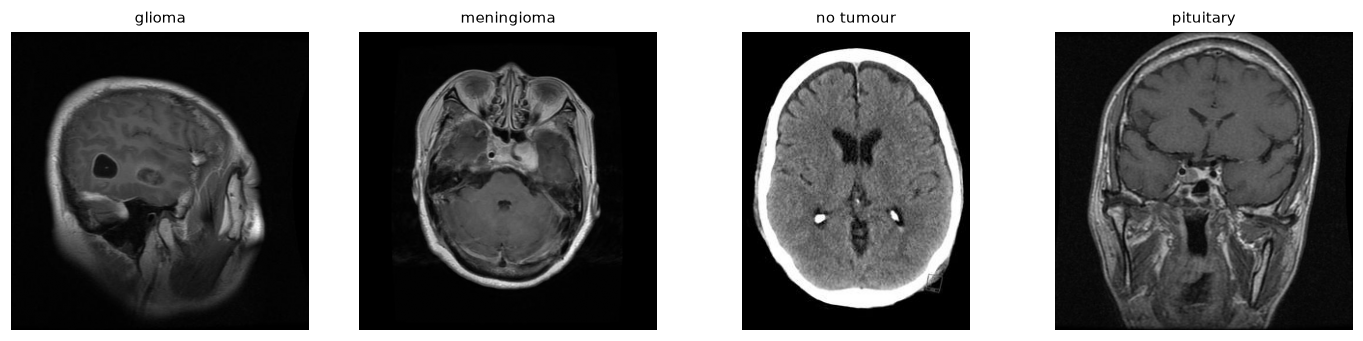

In [4]:
root = config.BRI_DATASET_PATH
rows = []
for part in ("Training", "Testing"):
    for folder in sorted((root / part).iterdir()):
        if folder.is_dir():
            rows.append([part, folder.name, len(list(folder.glob("*.jpg")))])
table(rows, ["split", "class", "images"])

examples = [next((root / "Testing" / c).glob("*.jpg")) for c in
            ("glioma", "meningioma", "notumor", "pituitary")]
show([read(p) for p in examples], ["glioma", "meningioma", "no tumour", "pituitary"], width=3.2)

## 4 · Held-out results, side by side

One test evaluation per method, on the same images. They are **not** an
ensemble and their numbers are not averaged: four independent pipelines, four
independent results.

In [5]:
rows = []
for spec in list_methods():
    m = metrics_for(spec.method_id)
    rows.append([spec.display_number, spec.short_name,
                 f"{m['accuracy']:.4f}" if m["accuracy"] is not None else "—",
                 f"{m['f1']:.4f}" if m["f1"] is not None else "—",
                 f"{m['auc']:.4f}" if m["auc"] is not None else "—",
                 f"{m['dice']:.4f}" if m["dice"] is not None else "—"])
table(sorted(rows), ["#", "method", "accuracy", "macro F1", "AUC", "seg Dice"])

#  method                                accuracy  macro F1  AUC     seg Dice
-  ------------------------------------  --------  --------  ------  --------
1  Pre-trained CNNs + Transfer Learning  0.9512    0.9495    0.9947  —       
2  Red Fox Optimized ZFNet               0.9764    0.9761    0.9953  —       
3  U-Net + ConvLSTM + SFLA               0.9695    0.9697    0.9944  0.6558  
4  MRI–SPECT Fusion                      0.9138    0.9103    0.9874  0.3725  


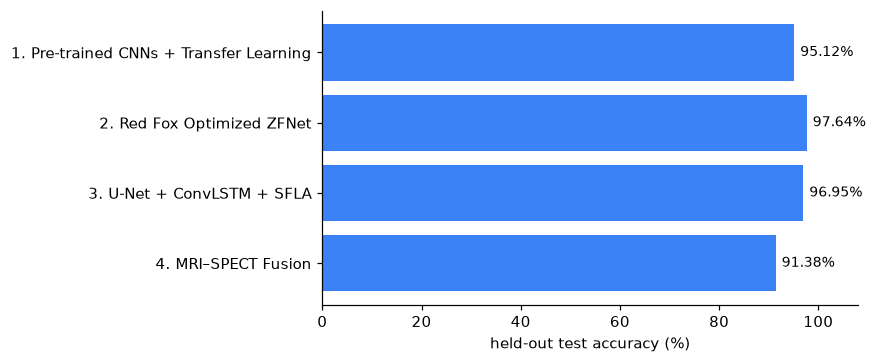

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
specs = sorted(list_methods(), key=lambda s: s.display_number)
values = [(metrics_for(s.method_id)["accuracy"] or 0) * 100 for s in specs]
bars = ax.barh([f"{s.display_number}. {s.short_name}" for s in specs], values, color="#3b82f6")
ax.bar_label(bars, fmt="%.2f%%", padding=4, fontsize=9)
ax.set_xlim(0, 108)
ax.set_xlabel("held-out test accuracy (%)")
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 5 · The same image through every method

Disagreement here is information, not noise: these are different architectures
trained separately, so where they disagree no vote among them is evidence.

In [7]:
image_path = next((config.BRI_DATASET_PATH / "Testing/meningioma").glob("*.jpg"))
image_bytes = image_path.read_bytes()
print("input:", image_path.name)

results = {}
for spec in sorted(list_methods(), key=lambda s: s.display_number):
    engine = load_engine(spec.method_id)
    results[spec.display_number] = (spec, engine.predict(image_bytes))

table([[n, s.short_name, r.prediction or "no prediction",
        f"{r.confidence:.2f}%" if r.confidence else "—", f"{r.inference_time_s:.2f}s"]
       for n, (s, r) in results.items()],
      ["#", "method", "prediction", "confidence", "time"])

input: Te-me_0304.jpg


#  method                                prediction  confidence  time 
-  ------------------------------------  ----------  ----------  -----
1  Pre-trained CNNs + Transfer Learning  Meningioma  83.79%      2.38s
2  Red Fox Optimized ZFNet               Meningioma  94.25%      0.14s
3  U-Net + ConvLSTM + SFLA               Glioma      98.54%      0.11s
4  MRI–SPECT Fusion                      Meningioma  90.46%      0.48s


Method 1 · Pre-trained CNNs + Transfer Learning → Meningioma (83.79%)


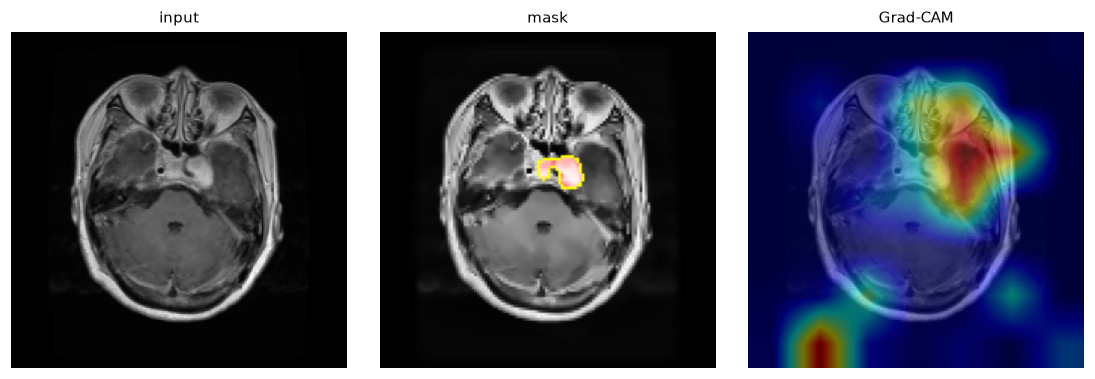

Method 2 · Red Fox Optimized ZFNet → Meningioma (94.25%)


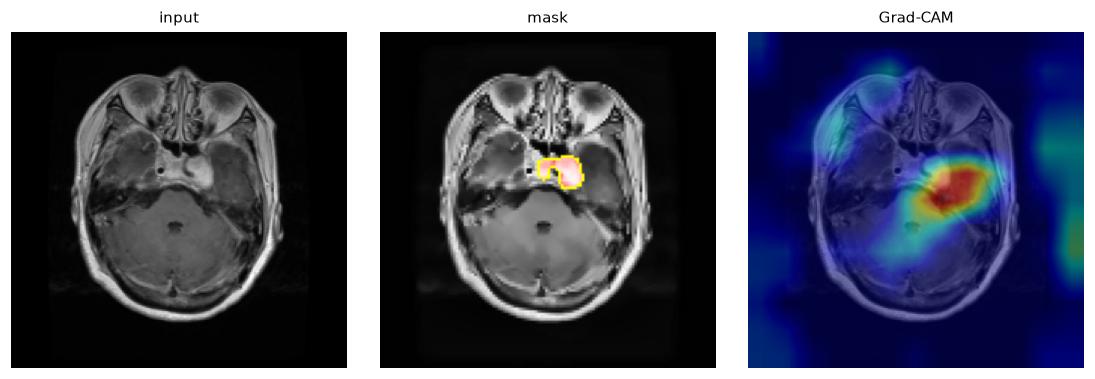

Method 3 · U-Net + ConvLSTM + SFLA → Glioma (98.54%)


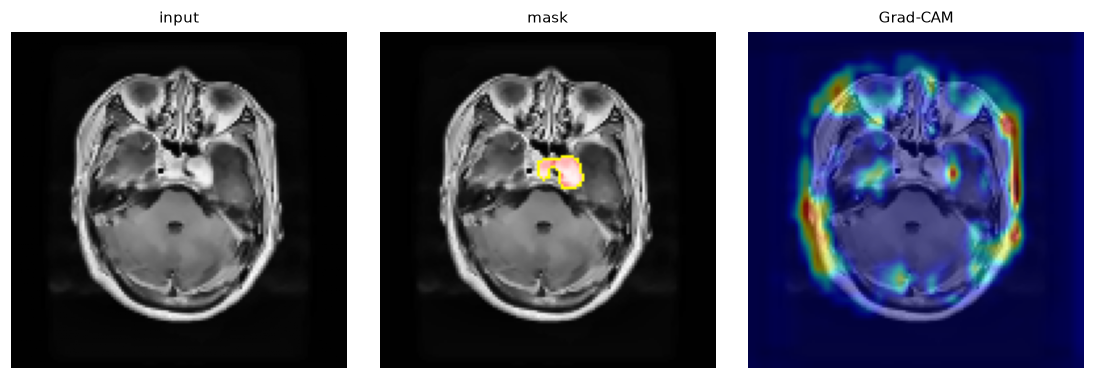

Method 4 · MRI–SPECT Fusion → Meningioma (90.46%)


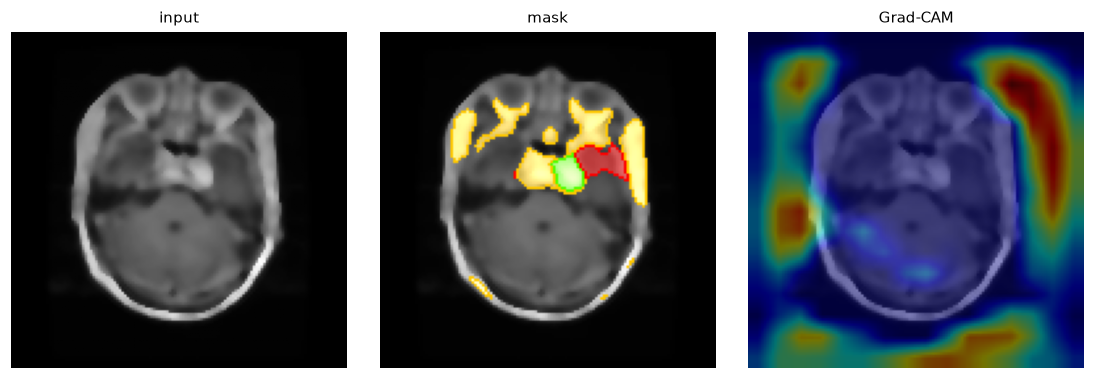

In [8]:
for number, (spec, result) in results.items():
    panels = [("input", result.original_path), ("mask", result.mask_path),
              ("Grad-CAM", result.overlay_path)]
    panels = [(label, path) for label, path in panels if path]
    print(f"Method {number} · {spec.short_name} → {result.prediction} ({result.confidence}%)")
    show([read(p) for _, p in panels], [label for label, _ in panels], width=3.4)

## 6 · Everything these results come with

The warnings are recorded by the training runs themselves and are part of each
result.

In [9]:
for spec in sorted(list_methods(), key=lambda s: s.display_number):
    warnings_seen = []
    for section, values in read_metrics(spec.method_id).items():
        if isinstance(values, dict):
            warnings_seen += [w for w in (values.get("warnings") or []) if w not in warnings_seen]
    print(f"── Method {spec.display_number}: {spec.short_name} " + "─" * 30)
    for warning in warnings_seen[:4]:
        print(" •", warning)
    print()

── Method 1: Pre-trained CNNs + Transfer Learning ──────────────────────────────
 • The Kaggle brain-MRI classification dataset carries no patient identifiers, so samples can only be grouped by image identity (training groups byte-identical copies together). Scores from this dataset may still be optimistic if the same patient appears under unrelated filenames.
 • Using the dataset's own Training/Testing split. It is an IMAGE-level split: this dataset ships no patient identifiers, so slices from one patient may appear on both sides and the test score can be optimistic.
 • Dropped 134 Training images that are byte-identical to a Testing image, so the test score is not inflated by memorised copies. The Testing set itself was not modified.
 • The fusion ensemble trains on cached frozen-backbone features, so no augmentation is applied: an augmented copy would need its own pass through all four backbones.

── Method 2: Red Fox Optimized ZFNet ──────────────────────────────
 • The Kaggle brai